# TP2 — Répondre par oui ou non : la classification binaire
**ÉNONCÉ** · Durée estimée : **une demi-journée**

## 🎯 Ce que vous allez apprendre
- Construire un réseau de **classification binaire** (sigmoïde, perte binary_crossentropy)
- Lire une **matrice de confusion** et calculer **précision** et **rappel** à la main
- Comprendre que **toutes les erreurs ne se valent pas** selon le contexte
- Déplacer le **seuil de décision** et mesurer le compromis, tracer la **courbe ROC**

## 🧰 Boîte à outils
Noms de fonctions et de classes utiles. **Aucun exemple d'appel n'est donné** : cherchez dans la documentation (scikit-learn, Keras, NumPy, matplotlib) comment les utiliser.

`load_breast_cancer`  ·  `train_test_split`  ·  `StandardScaler`  ·  `LogisticRegression`  ·  `keras.Sequential`  ·  `layers.Dense`  ·  `EarlyStopping`  ·  `model.predict`  ·  `np.sum`  ·  `confusion_matrix`  ·  `precision_score`  ·  `recall_score`  ·  `roc_auc_score`  ·  `roc_curve`

## 📘 Comment travailler
- Les cellules **déjà écrites** sont à lire et à exécuter.
- Les cellules **🎯 Étape** sont à **écrire vous-même**, à partir de la consigne.
- Après chaque étape, une cellule **✅ Contrôle** vérifie votre résultat. Respectez les **noms de variables** demandés.
- Les questions **✍️** demandent une réponse écrite : c'est là que vous montrez que vous avez compris.
- Bloqué ? Relisez l'indice, puis cherchez dans la documentation. Un message d'erreur se lit : la dernière ligne dit souvent ce qui ne va pas.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, confusion_matrix, precision_score, recall_score
from tensorflow import keras
from tensorflow.keras import layers, regularizers
keras.utils.set_random_seed(42)

def controle(condition, ok, ko):
    print("✅", ok) if condition else print("❌", ko)

## Étape 1 — Les données : détecter des tumeurs malignes
569 tumeurs, **30 mesures** par tumeur (taille, texture, forme des cellules…). On veut prédire si la tumeur est **maligne (1)** ou bénigne (0). Dans ce jeu, scikit-learn code l'inverse (0 = malin) : on le retourne pour que **1 = la chose à détecter**.

In [2]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()
X = data.data
y = 1 - data.target          # 1 = tumeur maligne
print(X.shape, "| part de tumeurs malignes :", round(y.mean(), 3))
pd.DataFrame(X[:, :5], columns=data.feature_names[:5]).head()

(569, 30) | part de tumeurs malignes : 0.373


,mean radius,mean texture,mean perimeter,mean area,mean smoothness
0,17.99,10.38,122.80,1001.0,0.11840
1,20.57,17.77,132.90,1326.0,0.08474
2,19.69,21.25,130.00,1203.0,0.10960
3,11.42,20.38,77.58,386.1,0.14250
4,20.29,14.34,135.10,1297.0,0.10030


## 🎯 Étape 2 — Découper et mettre à l'échelle
Les 30 colonnes ont des ordres de grandeur très différents (une aire vaut des centaines, une finesse vaut 0,1). On les **standardise**. ⚠️ La moyenne et l'écart-type se calculent sur l'**apprentissage seul**, sinon le test « souffle » des informations au modèle : c'est une **fuite de données**.

**À faire :** Découpez en `X_train`, `X_test`, `y_train`, `y_test` : **20 % de test**, **stratifié sur `y`** (mêmes proportions de malins dans les deux jeux), `random_state=42`. Puis standardisez `X_train` et `X_test` (fit sur le train seulement).

> 💡 **Indice** : `train_test_split(..., stratify=...)`. `StandardScaler` : `fit_transform` sur le train, `transform` sur le test.

In [3]:
# TODO : découper (stratifié), puis standardiser
# Découpage stratifié
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Standardisation
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [4]:
# ✅ Contrôle (ne pas modifier)
controle(X_train.shape == (455, 30) and X_test.shape == (114, 30) and abs(X_train.mean()) < 1e-6, 'Découpage et échelle corrects', 'Attendu (455, 30) et (114, 30), train de moyenne 0')

✅ Découpage et échelle corrects


## 🎯 Étape 3 — Les références à battre
Si **90 % des cas sont bénins**, répondre toujours « bénin » donne 90 % de bonnes réponses sans rien comprendre. On regarde donc deux références.

**À faire :** Calculez `acc_betise` (part de bonnes réponses en répondant **toujours la classe la plus fréquente du train**) et `acc_logistique` (précision d'une **régression logistique** sur le test).

> 💡 **Indice** : La classe la plus fréquente : `y_train.mean()`. `LogisticRegression(max_iter=2000)` puis `.score(X_test, y_test)`.

In [5]:
from sklearn.linear_model import LogisticRegression
# TODO : acc_betise et acc_logistique
acc_betise = max(y_train.mean(), 1 - y_train.mean())

modele_log = LogisticRegression(max_iter=2000)
modele_log.fit(X_train, y_train)
acc_logistique = modele_log.score(X_test, y_test)


In [6]:
# ✅ Contrôle (ne pas modifier)
controle(0.55 < acc_betise < 0.7 and acc_logistique > 0.93, 'Références plausibles', 'Attendu : « toujours pareil » ≈ 0.6 et régression logistique > 0.93')

✅ Références plausibles


## 🎯 Étape 4 — Construire le réseau
Pour une réponse **oui / non**, la sortie est **un neurone avec une sigmoïde** (une probabilité entre 0 et 1) et la perte est la **binary_crossentropy**, qui punit surtout les réponses **sûres et fausses**.

**À faire :** Construisez `modele` : entrée de 30, une couche de **16 neurones (ReLU)**, une de **8 (ReLU)**, une sortie de 1 neurone **sigmoïde**. Compilez avec **adam**, **binary_crossentropy** et la métrique **accuracy**.

> 💡 **Indice** : Même squelette qu'au TP1. Seuls la **sortie** et la **perte** changent.

In [7]:
keras.utils.set_random_seed(42)
# TODO : construire et compiler modele
modele = keras.Sequential([
    layers.Input(shape=(30,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

modele.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [8]:
# ✅ Contrôle (ne pas modifier)
controle(modele.count_params() == 641, 'Réseau correct : 641 paramètres', 'Attendu 641 paramètres, obtenu ' + str(modele.count_params()))

✅ Réseau correct : 641 paramètres


## 🎯 Étape 5 — Entraîner avec arrêt précoce
Plutôt que de deviner le bon nombre d'epochs, on laisse le réseau s'arrêter **quand la perte de validation cesse de s'améliorer** (`EarlyStopping`), et on **reprend les meilleurs poids**.

**À faire :** Entraînez `modele` : **100 epochs maximum**, batch de 16, 20 % de validation, avec un arrêt précoce de **patience 10** qui restaure les meilleurs poids. Stockez le résultat dans `histoire`.

> 💡 **Indice** : `keras.callbacks.EarlyStopping(monitor=..., patience=..., restore_best_weights=...)`, passé via l'argument `callbacks`.

In [9]:
# TODO : entraîner avec arrêt précoce
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

histoire = modele.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=0
)

In [10]:
# ✅ Contrôle (ne pas modifier)
controle(len(histoire.history['loss']) < 100, 'Arrêt automatique avant 100 epochs (%d)' % len(histoire.history['loss']), 'Le réseau est allé jusqu\'à 100 epochs : l\'arrêt précoce n\'a pas joué')

✅ Arrêt automatique avant 100 epochs (84)


## Étape 6 — Les courbes
Perte et précision, sur l'apprentissage (bleu) et la validation (orange).

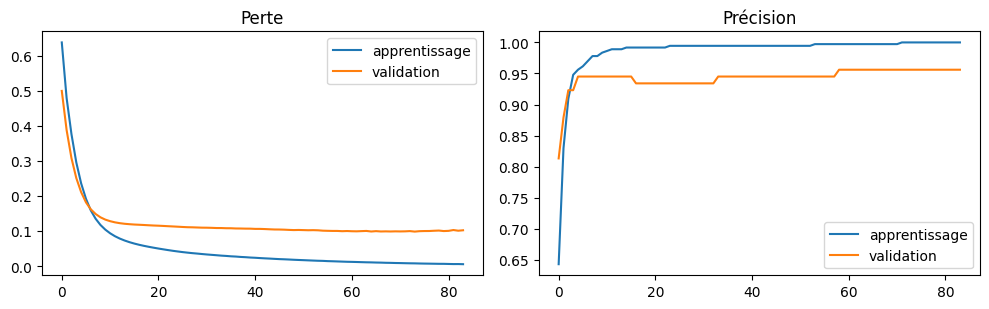

In [11]:
h = histoire.history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h["loss"], label="apprentissage"); ax[0].plot(h["val_loss"], label="validation"); ax[0].set_title("Perte"); ax[0].legend()
ax[1].plot(h["accuracy"], label="apprentissage"); ax[1].plot(h["val_accuracy"], label="validation"); ax[1].set_title("Précision"); ax[1].legend()
plt.tight_layout(); plt.show()

## 🎯 Étape 7 — La matrice de confusion, calculée à la main
Au lieu d'un seul pourcentage, on **compte les quatre cas** : **VP** (malin détecté), **VN** (bénin reconnu), **FP** (fausse alerte : bénin annoncé malin), **FN** (tumeur maligne **ratée**).

- **Précision** = `VP / (VP + FP)` : « quand le modèle crie au malin, a-t-il raison ? »
- **Rappel** = `VP / (VP + FN)` : « parmi les vraies tumeurs malignes, combien a-t-on trouvées ? »

**À faire :** Calculez `proba` (probabilités prédites sur `X_test`, à plat) puis `pred` (classe prédite au **seuil 0,5**). Comptez `VP`, `VN`, `FP`, `FN` avec NumPy (sans bibliothèque de métriques), puis `precision` et `rappel`.

> 💡 **Indice** : `np.sum((pred == 1) & (y_test == 1))` compte les VP. Faites de même pour les trois autres cas.

In [12]:
# TODO : proba, pred, VP, VN, FP, FN, precision, rappel
proba = modele.predict(X_test, verbose=0).ravel()
pred = (proba >= 0.5).astype(int)

VP = np.sum((pred == 1) & (y_test == 1)) # Vrais Positifs (Tumeurs trouvées)
VN = np.sum((pred == 0) & (y_test == 0)) # Vrais Négatifs (Sains confirmés)
FP = np.sum((pred == 1) & (y_test == 0)) # Faux Positifs (Fausses alertes)
FN = np.sum((pred == 0) & (y_test == 1)) # Faux Négatifs (Tumeurs ratées)

precision = VP / (VP + FP)
rappel = VP / (VP + FN)

In [13]:
# ✅ Contrôle (ne pas modifier)
controle(VP + VN + FP + FN == 114 and abs(precision - precision_score(y_test, pred)) < 1e-9 and abs(rappel - recall_score(y_test, pred)) < 1e-9, 'Vos comptes retrouvent ceux de scikit-learn', 'Vos nombres ne correspondent pas à precision_score / recall_score')

✅ Vos comptes retrouvent ceux de scikit-learn


### ✍️ Question
**Dans ce contexte médical, quelle erreur est la plus grave : le faux positif ou le faux négatif ? Que disent vos chiffres ?**

Dans ce contexte médical de détection de tumeurs, le faux négatif (dire à un patient malade qu'il est en bonne santé) est de loin l'erreur la plus grave car cela retarde un traitement vital. À l'inverse, un faux positif n'est qu'une fausse alerte qui entraînera des examens complémentaires. Nos chiffres avec le calcul du rappel montrent qu'au seuil par défaut de 0,5, le modèle risque encore de rater quelques tumeurs, ce qui est inacceptable pour un dépistage.

>

## 🎯 Étape 8 — Déplacer le seuil
Le seuil 0,5 est un **choix par défaut**, pas une vérité. **Baisser** le seuil : le modèle crie plus facilement au malin (moins de tumeurs ratées, plus de fausses alertes).

**À faire :** Pour les seuils **0,5 / 0,3 / 0,1 / 0,05**, calculez la **précision**, le **rappel** et le **nombre de tumeurs malignes ratées (FN)**. Rangez le tout dans un tableau pandas `tableau` (une ligne par seuil).

> 💡 **Indice** : Une boucle sur les seuils, `pred = (proba > seuil)`, puis `pd.DataFrame(liste_de_dictionnaires)`.

In [14]:
# TODO : construire le tableau pour les 4 seuils
lignes = []

for seuil in [0.5, 0.3, 0.1, 0.05]:
    p = (proba > seuil).astype(int)

    vp = np.sum((p == 1) & (y_test == 1))
    fp = np.sum((p == 1) & (y_test == 0))
    fn = np.sum((p == 0) & (y_test == 1))

    prec = vp / (vp + fp) if (vp + fp) > 0 else 0
    rap = vp / (vp + fn) if (vp + fn) > 0 else 0

    lignes.append({
        'seuil': seuil,
        'précision': prec,
        'rappel': rap,
        'tumeurs ratées (FN)': fn
    })

tableau = pd.DataFrame(lignes)

In [15]:
# ✅ Contrôle (ne pas modifier)
controle(tableau['rappel'].is_monotonic_increasing and tableau['tumeurs ratées (FN)'].is_monotonic_decreasing, 'Plus le seuil baisse, plus le rappel monte', 'Attendu : le rappel augmente et les FN diminuent quand le seuil baisse')

✅ Plus le seuil baisse, plus le rappel monte


### ✍️ Question
**Quel seuil choisiriez-vous pour un dépistage ? Que payez-vous en échange ?**

Pour un dépistage, je choisirais un seuil très bas (par exemple 0,05 ou 0,1) afin d'être alerté au moindre doute et d'avoir un rappel proche de 100% (aucune tumeur ratée). En échange de cette sécurité maximale, je paye le prix d'une perte de précision : le modèle va générer beaucoup de faux positifs (fausses alertes), ce qui nécessitera des examens médicaux supplémentaires inutiles pour des patients en bonne santé.

>

## 🎯 Étape 9 — La courbe ROC
Au lieu de choisir un seuil, la **courbe ROC** les montre **tous** : en abscisse le taux de fausses alertes, en ordonnée le rappel. L'**AUC** (aire sous la courbe) résume la capacité à séparer les deux classes : **0,5 = hasard, 1 = parfait**.

**À faire :** Calculez `auc` avec `proba` et tracez la courbe ROC (avec la diagonale du hasard).

> 💡 **Indice** : `roc_curve` renvoie trois tableaux ; `roc_auc_score` renvoie un nombre.

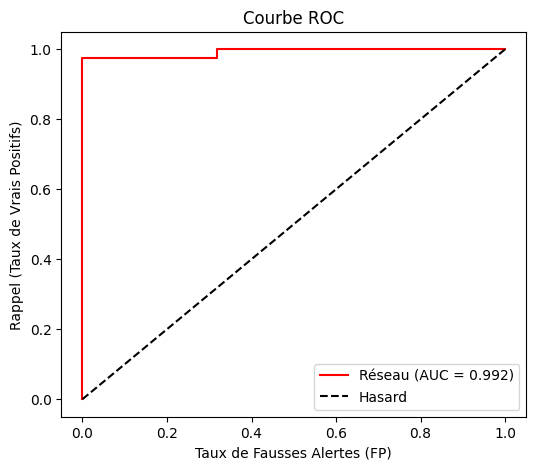

In [16]:
from sklearn.metrics import roc_auc_score, roc_curve
# TODO : auc et courbe ROC
auc = roc_auc_score(y_test, proba)
fpr, tpr, thresholds = roc_curve(y_test, proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"Réseau (AUC = {auc:.3f})", color="red")
plt.plot([0, 1], [0, 1], 'k--', label="Hasard")
plt.xlabel("Taux de Fausses Alertes (FP)")
plt.ylabel("Rappel (Taux de Vrais Positifs)")
plt.title("Courbe ROC")
plt.legend()
plt.show()

In [17]:
# ✅ Contrôle (ne pas modifier)
controle(auc > 0.95, 'AUC = %.3f' % auc, 'Attendu une AUC supérieure à 0.95')

✅ AUC = 0.992


## ✅ Ce qu'il faut retenir
- **Classification binaire** : sortie sigmoïde, perte **binary_crossentropy**.
- **Matrice de confusion** : VP, VN, FP, FN. **Précision** = « quand j'annonce, ai-je raison ? », **rappel** = « combien en ai-je retrouvé ? ».
- **Toutes les erreurs ne se valent pas** : le contexte décide laquelle est la plus grave.
- Le **seuil** règle le compromis précision / rappel ; la **courbe ROC / AUC** résume tous les seuils.
- **Standardiser avec les statistiques de l'apprentissage seul**, toujours.